## Homework 3


In [1]:
import pandas as pd
from matplotlib import pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mutual_info_score

url = (
    "https://raw.githubusercontent.com/DataTalksClub/"
    "machine-learning-zoomcamp/main/cohorts/2026/data/"
    "course_lead_scoring_2026.csv"
)

target = "converted"
categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = [
    "annual_income",
    "number_of_courses_viewed",
    "interaction_count",
    "lead_score",
]
features = categorical + numerical

df = pd.read_csv(url)
df.head()


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## EDA: количество регистраций



(5000, 9)

converted
0    2117
1    2883
Name: count, dtype: int64

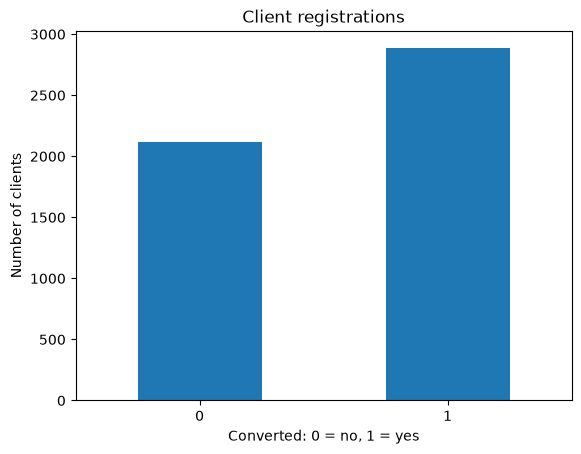

In [2]:
display(df.shape)
display(df[target].value_counts().sort_index())

df[target].value_counts().sort_index().plot.bar(rot=0)
plt.xlabel("Converted: 0 = no, 1 = yes")
plt.ylabel("Number of clients")
plt.title("Client registrations")
plt.show()


## Подготовка данных


In [3]:
missing_values = df[features].isna().sum()
display(missing_values)

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

assert df[features + [target]].isna().sum().sum() == 0


lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
dtype: int64

## Question 1

Нахожу самое частое значение в колонке industry. value_counts считает, сколько раз встретилось каждое значение, и ставит самое частое первым.


In [5]:
industry_counts = df["industry"].value_counts()
display(industry_counts)

answer_q1 = industry_counts.index[0]
print("Answer Q1:", answer_q1)


industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

Answer Q1: technology


## Question 2

Корреляция показывает, насколько два числовых признака изменяются вместе. Здесь выбираю наибольшую корреляцию только среди четырёх пар, перечисленных в задании.


In [6]:
correlation_matrix = df[numerical].corr()
display(correlation_matrix)

pairs = [
    ("interaction_count", "lead_score"),
    ("number_of_courses_viewed", "lead_score"),
    ("number_of_courses_viewed", "interaction_count"),
    ("annual_income", "interaction_count"),
]

results_q2 = pd.DataFrame([
    {
        "feature_1": first,
        "feature_2": second,
        "correlation": correlation_matrix.loc[first, second],
    }
    for first, second in pairs
])
display(results_q2.sort_values("correlation", ascending=False))

best_pair = results_q2.loc[results_q2["correlation"].idxmax()]
answer_q2 = best_pair["feature_1"] + " and " + best_pair["feature_2"]
print("Answer Q2:", answer_q2)


,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.161300,0.122842,0.229496
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204
interaction_count,0.122842,0.721609,1.000000,0.915746
lead_score,0.229496,0.757204,0.915746,1.000000


,feature_1,feature_2,correlation
0,interaction_count,lead_score,0.915746
1,number_of_courses_viewed,lead_score,0.757204
2,number_of_courses_viewed,interaction_count,0.721609
3,annual_income,interaction_count,0.122842


Answer Q2: interaction_count and lead_score


## Разделение данных

Сначала откладываю 20% строк для test. Затем из оставшихся 80% выделяю четверть для validation: 80% × 0.25 = 20% всей таблицы. Получаются train 60%, validation 20%, test 20%.

random_state=42 позволяет при повторном запуске получить то же разделение. Ответы `converted` сохраняю отдельно в y_ и убираю из признаков


In [7]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

df_train = df_train.drop(columns=[target]).reset_index(drop=True)
df_val = df_val.drop(columns=[target]).reset_index(drop=True)
df_test = df_test.drop(columns=[target]).reset_index(drop=True)

display(pd.DataFrame({
    "part": ["train", "validation", "test"],
    "rows": [len(df_train), len(df_val), len(df_test)],
}))

assert target not in df_train.columns
assert target not in df_val.columns
assert target not in df_test.columns
assert len(df_train) + len(df_val) + len(df_test) == len(df)


,part,rows
0,train,3000
1,validation,1000
2,test,1000


## Question 3

Mutual information показывает, насколько знание категории помогает узнать ответ converted. Чем выше значение, тем сильнее связь. Считаю только по train и округляю до двух знаков.


In [8]:
results_q3 = pd.DataFrame([
    {
        "feature": column,
        "mutual_information": mutual_info_score(df_train[column], y_train),
    }
    for column in categorical
])
results_q3["MI rounded"] = results_q3["mutual_information"].map(
    lambda score: round(score, 2)
)
display(results_q3.sort_values("MI rounded", ascending=False))

answer_q3 = results_q3.loc[results_q3["MI rounded"].idxmax(), "feature"]
print("Answer Q3:", answer_q3)


,feature,mutual_information,MI rounded
0,lead_source,0.034346,0.03
2,employment_status,0.018966,0.02
1,industry,0.001995,0.00
3,location,0.001043,0.00


Answer Q3: lead_source


## Вспомогательные функции для вопросов 4-6

DictVectorizer превращает категории в отдельные колонки с 0 и 1, а числовые признаки сохраняет числами. Набор колонок определяю по train; validation преобразую по тем же правилам.

fit() обучает модель, predict() возвращает её ответы 0 или 1. Accuracy = количество правильных ответов / количество всех ответов. 


In [9]:
def train_model(train_df, train_y, selected_features, C=1.0):
    train_dicts = train_df[selected_features].to_dict(orient="records")

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dicts)

    model = LogisticRegression(
        solver="liblinear",
        C=C,
        max_iter=1000,
        random_state=42,
    )
    model.fit(X_train, train_y)
    return dv, model


def validation_accuracy(dv, model, validation_df, validation_y, selected_features):
    validation_dicts = validation_df[selected_features].to_dict(orient="records")
    X_val = dv.transform(validation_dicts)
    predictions = model.predict(X_val)
    return accuracy_score(validation_y, predictions)


## Question 4

Обучаю логистическую регрессию на всех восьми признаках. Проверяю на validation и округляю accuracy до двух знаков.


In [10]:
dv, model = train_model(df_train, y_train, features, C=1.0)
baseline_accuracy = validation_accuracy(dv, model, df_val, y_val, features)

answer_q4 = round(baseline_accuracy, 2)
assert answer_q4 in [0.55, 0.65, 0.75, 0.85], (
    "Accuracy does not match the homework options: check the data and settings."
)

print("Validation accuracy:", baseline_accuracy)
print("Answer Q4:", answer_q4)


Validation accuracy: 0.645
Answer Q4: 0.65


## Question 5: исключение признаков

По очереди убираю один признак и заново обучаю модель. Разница = accuracy со всеми признаками - accuracy без этого признака.

Разница может быть отрицательной: значит, без признака результат стал лучше. Для ответа выбираю наименьшую разницу среди трёх вариантов из задания.


In [11]:
scores_q5 = []

for excluded_feature in features:
    selected_features = [
        feature for feature in features if feature != excluded_feature
    ]
    dv_without, model_without = train_model(
        df_train, y_train, selected_features, C=1.0
    )
    score = validation_accuracy(
        dv_without, model_without, df_val, y_val, selected_features
    )
    scores_q5.append({
        "excluded_feature": excluded_feature,
        "accuracy_without_feature": score,
        "difference": baseline_accuracy - score,
    })

results_q5 = pd.DataFrame(scores_q5)
display(results_q5.sort_values("difference"))

options_q5 = ["lead_source", "number_of_courses_viewed", "interaction_count"]
candidate_results = results_q5[
    results_q5["excluded_feature"].isin(options_q5)
]
answer_q5 = candidate_results.loc[
    candidate_results["difference"].idxmin(), "excluded_feature"
]
print("Baseline accuracy:", baseline_accuracy)
print("Answer Q5:", answer_q5)


,excluded_feature,accuracy_without_feature,difference
4,annual_income,0.724,-0.079
1,industry,0.645,0.000
3,location,0.645,0.000
2,employment_status,0.645,0.000
7,lead_score,0.644,0.001
5,number_of_courses_viewed,0.643,0.002
0,lead_source,0.642,0.003
6,interaction_count,0.601,0.044


Baseline accuracy: 0.645
Answer Q5: number_of_courses_viewed


## Question 6: регуляризация

Регуляризация ограничивает величину весов модели. Меньшее C означает более сильное ограничение.

Проверяю четыре значения C на всех признаках. Сравниваю accuracy, округлённую до трёх знаков. При одинаковом результате выбираю наименьшее C.


In [12]:
C_values = [0.000001, 0.00001, 0.0001, 0.001]
scores_q6 = []

for C in C_values:
    dv_regularized, model_regularized = train_model(
        df_train, y_train, features, C=C
    )
    score = validation_accuracy(
        dv_regularized, model_regularized, df_val, y_val, features
    )
    scores_q6.append({
        "C": C,
        "accuracy": score,
        "accuracy rounded": round(score, 3),
    })

results_q6 = pd.DataFrame(scores_q6)
display(results_q6)

best_result = results_q6.sort_values(
    ["accuracy rounded", "C"],
    ascending=[False, True],
).iloc[0]
answer_q6 = float(best_result["C"])
print("Answer Q6:", format(answer_q6, ".6f"))


,C,accuracy,accuracy rounded
0,0.000001,0.598,0.598
1,0.000010,0.598,0.598
2,0.000100,0.613,0.613
3,0.001000,0.645,0.645


Answer Q6: 0.001000


## Ответы

Сводка результатов, полученных кодом выше. Отправка ответов на сайт курса выполняется отдельно.


In [12]:
answers = pd.DataFrame({
    "question": ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"],
    "answer": [
        answer_q1,
        answer_q2,
        answer_q3,
        answer_q4,
        answer_q5,
        format(answer_q6, ".6f"),
    ],
})
display(answers)


,question,answer
0,Q1,technology
1,Q2,interaction_count and lead_score
2,Q3,lead_source
3,Q4,0.65
4,Q5,number_of_courses_viewed
5,Q6,0.001000
